# Data Scientist Professional Practical Exam Submission

**Use this template to write up your summary for submission. Code in Python or R needs to be included.**


## 📝 Task List

Your written report should include both code, output and written text summaries of the following:
- Data Validation:   
  - Describe validation and cleaning steps for every column in the data 
- Exploratory Analysis:  
  - Include two different graphics showing single variables only to demonstrate the characteristics of data  
  - Include at least one graphic showing two or more variables to represent the relationship between features
  - Describe your findings
- Model Development
  - Include your reasons for selecting the models you use as well as a statement of the problem type
  - Code to fit the baseline and comparison models
- Model Evaluation
  - Describe the performance of the two models based on an appropriate metric
- Business Metrics
  - Define a way to compare your model performance to the business
  - Describe how your models perform using this approach
- Final summary including recommendations that the business should undertake

*Start writing report here..*

In [317]:
# Start coding here...
'''In this notebook, our goal is to forecast recipes that are expected to achieve an 80% popularity rate while reducing the visibility of those with low popularity. We’ll start by validating the data, which involves steps like removing duplicate entries, handling missing data, and adjusting column data types in the dataframe. Next, we’ll perform exploratory data analysis to uncover meaningful patterns and trends. Based on these findings, we’ll build and evaluate a machine learning model. Finally, we’ll ensure our solution aligns with business goals and offer actionable recommendations to support the company’s success.
'''


'In this notebook, our goal is to forecast recipes that are expected to achieve an 80% popularity rate while reducing the visibility of those with low popularity. We’ll start by validating the data, which involves steps like removing duplicate entries, handling missing data, and adjusting column data types in the dataframe. Next, we’ll perform exploratory data analysis to uncover meaningful patterns and trends. Based on these findings, we’ll build and evaluate a machine learning model. Finally, we’ll ensure our solution aligns with business goals and offer actionable recommendations to support the company’s success.\n'

In [318]:
#Import neccessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import yeojohnson
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [319]:
#Read the csv file to start data cleaning and validation
recipe_site_traffic = pd.read_csv('recipe_site_traffic_2212.csv')
#Read the first 10 rows of our dataset
recipe_site_traffic.head(10)

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN
5,6,691.15,3.46,1.65,53.93,One Dish Meal,2,High
6,7,183.94,47.95,9.75,46.71,Chicken Breast,4,NaN
7,8,299.14,3.17,0.40,32.40,Lunch/Snacks,4,NaN
8,9,538.52,3.78,3.37,3.79,Pork,6,High
9,10,248.28,48.54,3.99,113.85,Chicken,2,NaN


In [320]:
'''We’ll check the dataset’s dimensions by looking at the number of rows and columns, as well as the column names and their data types. We’ll also determine how many non-null values are in each column. If we find any mismatched data types or missing values, we’ll address them as needed to ensure the dataset’s integrity.
'''

'We’ll check the dataset’s dimensions by looking at the number of rows and columns, as well as the column names and their data types. We’ll also determine how many non-null values are in each column. If we find any mismatched data types or missing values, we’ll address them as needed to ensure the dataset’s integrity.\n'

In [321]:
#Checking the dataset's information
recipe_site_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    object 
 6   servings      947 non-null    object 
 7   high_traffic  574 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 59.3+ KB


In [322]:
'''The first column to address is “category,” which is currently an object type. We need to check if any rows require changes before converting it to a categorical type. To start, we’ll examine the value distribution to better understand the data.
'''

'The first column to address is “category,” which is currently an object type. We need to check if any rows require changes before converting it to a categorical type. To start, we’ll examine the value distribution to better understand the data.\n'

In [323]:
#Checking the value distribution of 'category' column
recipe_site_traffic['category'].value_counts()

Breakfast         106
Chicken Breast     98
Beverages          92
Lunch/Snacks       89
Potato             88
Pork               84
Vegetable          83
Dessert            83
Meat               79
Chicken            74
One Dish Meal      71
Name: category, dtype: int64

In [324]:
'''An additional category, “Chicken Breast,” appears in the “category” column. However, since the accepted categories are limited to ‘Lunch/Snacks’, ‘Beverages’, ‘Potato’, ‘Vegetable’, ‘Meat’, ‘Chicken’, ‘Pork’, ‘Dessert’, ‘Breakfast’, and ‘One Dish Meal,’ “Chicken Breast” does not fit the criteria. Therefore, it makes sense to reclassify “Chicken Breast” under the “Chicken” category. We will proceed with this adjustment.
'''

'An additional category, “Chicken Breast,” appears in the “category” column. However, since the accepted categories are limited to ‘Lunch/Snacks’, ‘Beverages’, ‘Potato’, ‘Vegetable’, ‘Meat’, ‘Chicken’, ‘Pork’, ‘Dessert’, ‘Breakfast’, and ‘One Dish Meal,’ “Chicken Breast” does not fit the criteria. Therefore, it makes sense to reclassify “Chicken Breast” under the “Chicken” category. We will proceed with this adjustment.\n'

In [325]:
#Removing "breast" from "chicken breast" value in "category" column.
recipe_site_traffic['category'] = recipe_site_traffic['category'].str.replace(' Breast', '')
#Checking "category" column to verify the if changes have been made
recipe_site_traffic['category'].value_counts()

Chicken          172
Breakfast        106
Beverages         92
Lunch/Snacks      89
Potato            88
Pork              84
Vegetable         83
Dessert           83
Meat              79
One Dish Meal     71
Name: category, dtype: int64

In [326]:
#Converting category column into category data type
recipe_site_traffic['category'] = recipe_site_traffic['category'].astype('category')
#Moving foward to the servings column by checking the value distribution
recipe_site_traffic['servings'].value_counts()

4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: servings, dtype: int64

In [327]:
'''Checking the 'servings' column there are some values with numeric value and 'as a snack' pharse which is not required, so we have to replace the pharse 'as a snack' with thier numeric values.'''

"Checking the 'servings' column there are some values with numeric value and 'as a snack' pharse which is not required, so we have to replace the pharse 'as a snack' with thier numeric values."

In [328]:
#Removing "as a snack" phrase with thier numerical corresponding components
recipe_site_traffic['servings'] = recipe_site_traffic['servings'].str.replace(' as a snack', '').str.strip()
#checking the servings column again
recipe_site_traffic['servings'].value_counts()


4    391
6    198
2    183
1    175
Name: servings, dtype: int64

In [329]:
'''Since the “servings” column consists entirely of integers, we’ll convert its data type to an integer. Although it’s numeric, it behaves more like a categorical variable. We’ll keep it as an integer for the time being, knowing that it will need to be switched back to this format when we develop and evaluate our model.
'''

'Since the “servings” column consists entirely of integers, we’ll convert its data type to an integer. Although it’s numeric, it behaves more like a categorical variable. We’ll keep it as an integer for the time being, knowing that it will need to be switched back to this format when we develop and evaluate our model.\n'

In [330]:
recipe_site_traffic['servings'] = recipe_site_traffic['servings'].astype('int64')

In [331]:
'''Given the “high_traffic” column is currently classified as an object, we need to inspect the distribution of its values. This will help us decide on the best way to convert its data type.
'''

'Given the “high_traffic” column is currently classified as an object, we need to inspect the distribution of its values. This will help us decide on the best way to convert its data type.\n'

In [332]:
#Checking the value distribution of 'high_traffic' column
recipe_site_traffic['high_traffic'].value_counts()

High    574
Name: high_traffic, dtype: int64

In [333]:
#Replacing the values with 'high' as true and NaN to False
recipe_site_traffic['high_traffic'] = np.where(recipe_site_traffic['high_traffic'] == 'High', True, False)
#Rechecking the  value distribution 
recipe_site_traffic['high_traffic'].value_counts()

True     574
False    373
Name: high_traffic, dtype: int64

In [334]:
'''Since the “high_traffic” column only has one unique value, “High,” we’ll interpret the missing entries as representing “Low” traffic. We converted this column to a boolean data type, assigning True to “High” and False to “Low.”
'''

'Since the “high_traffic” column only has one unique value, “High,” we’ll interpret the missing entries as representing “Low” traffic. We converted this column to a boolean data type, assigning True to “High” and False to “Low.”\n'

In [335]:
#The next thing to do is to check for the missing value in each column
recipe_site_traffic.isna().sum()

recipe           0
calories        52
carbohydrate    52
sugar           52
protein         52
category         0
servings         0
high_traffic     0
dtype: int64

In [336]:
#Drop missing values
recipe_site_traffic = recipe_site_traffic.dropna().reset_index(drop=True)

#Rechecking missing values in columns
recipe_site_traffic.isna().sum()

recipe          0
calories        0
carbohydrate    0
sugar           0
protein         0
category        0
servings        0
high_traffic    0
dtype: int64

In [337]:
#checking the summary of dataframe's structure
recipe_site_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 895 entries, 0 to 894
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   recipe        895 non-null    int64   
 1   calories      895 non-null    float64 
 2   carbohydrate  895 non-null    float64 
 3   sugar         895 non-null    float64 
 4   protein       895 non-null    float64 
 5   category      895 non-null    category
 6   servings      895 non-null    int64   
 7   high_traffic  895 non-null    bool    
dtypes: bool(1), category(1), float64(4), int64(2)
memory usage: 44.2 KB


In [338]:
'''After finishing data validation and cleaning, the dataframe is ready for exploratory analysis. Next, we’ll calculate descriptive statistics for all numerical columns to gain deeper insights into the data’s characteristics.
'''

'After finishing data validation and cleaning, the dataframe is ready for exploratory analysis. Next, we’ll calculate descriptive statistics for all numerical columns to gain deeper insights into the data’s characteristics.\n'

In [339]:
recipe_site_traffic.describe()

,recipe,calories,carbohydrate,sugar,protein,servings
count,895.000000,895.000000,895.000000,895.000000,895.000000,895.000000
mean,473.652514,435.939196,35.069676,9.046547,24.149296,3.458101
std,272.763283,453.020997,43.949032,14.679176,36.369739,1.735979
min,2.000000,0.140000,0.030000,0.010000,0.000000,1.000000
25%,237.500000,110.430000,8.375000,1.690000,3.195000,2.000000
50%,475.000000,288.550000,21.480000,4.550000,10.800000,4.000000
75%,708.500000,597.650000,44.965000,9.800000,30.200000,4.000000
max,947.000000,3633.160000,530.420000,148.750000,363.360000,6.000000


In [340]:
'''Reviewing the descriptive statistics, we observe considerable variability, especially in the calories and nutrient-related columns, as reflected by the high standard deviations. The quantile values also suggest the presence of outliers, which contribute to skewed distributions. Therefore, it’s clear that the data is not normally distributed.
'''

'Reviewing the descriptive statistics, we observe considerable variability, especially in the calories and nutrient-related columns, as reflected by the high standard deviations. The quantile values also suggest the presence of outliers, which contribute to skewed distributions. Therefore, it’s clear that the data is not normally distributed.\n'

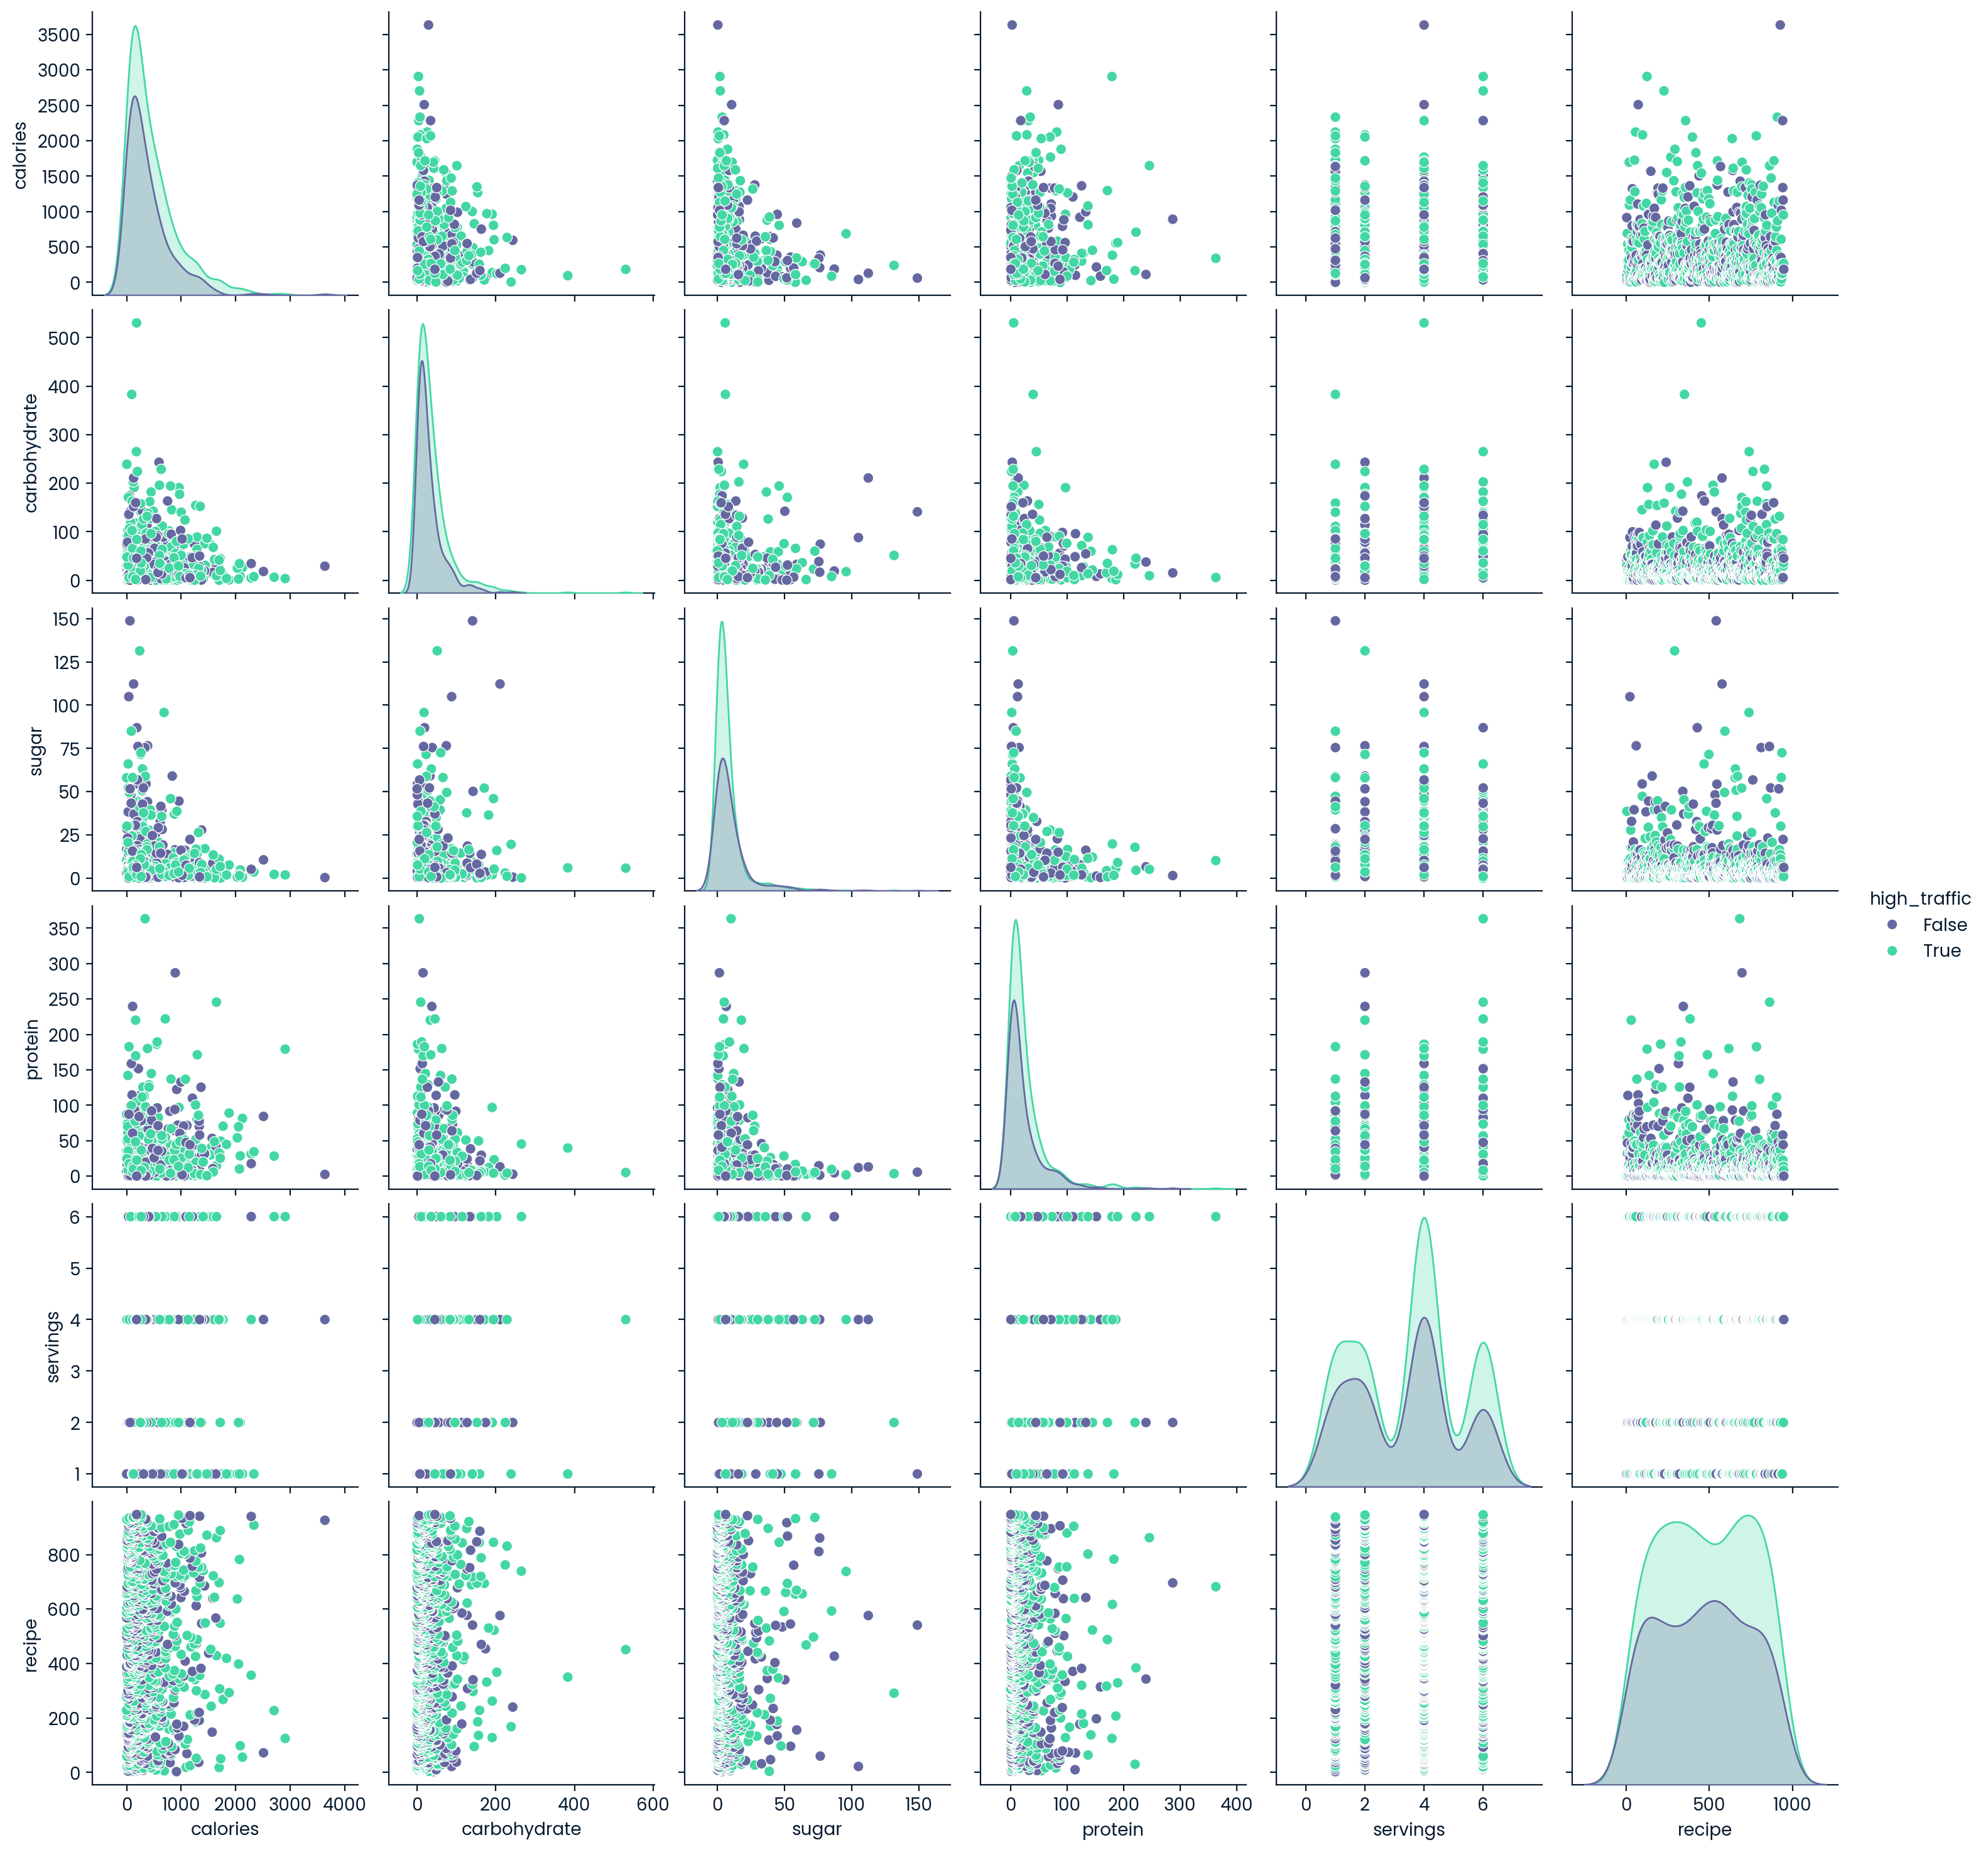

In [341]:
#Filtering columns neccesary for the analysis
filtered_column = ['calories','carbohydrate','sugar','protein','category','servings','high_traffic', 'recipe']
sns.pairplot(recipe_site_traffic[filtered_column], hue='high_traffic')
plt.show()

In [342]:
'''Based on the plot, it's apparent that there isn't a significant correlation between these columns.

Next, we'll proceed to generate a histogram to visualize the distribution of calories within the recipes.
'''

"Based on the plot, it's apparent that there isn't a significant correlation between these columns.\n\nNext, we'll proceed to generate a histogram to visualize the distribution of calories within the recipes.\n"

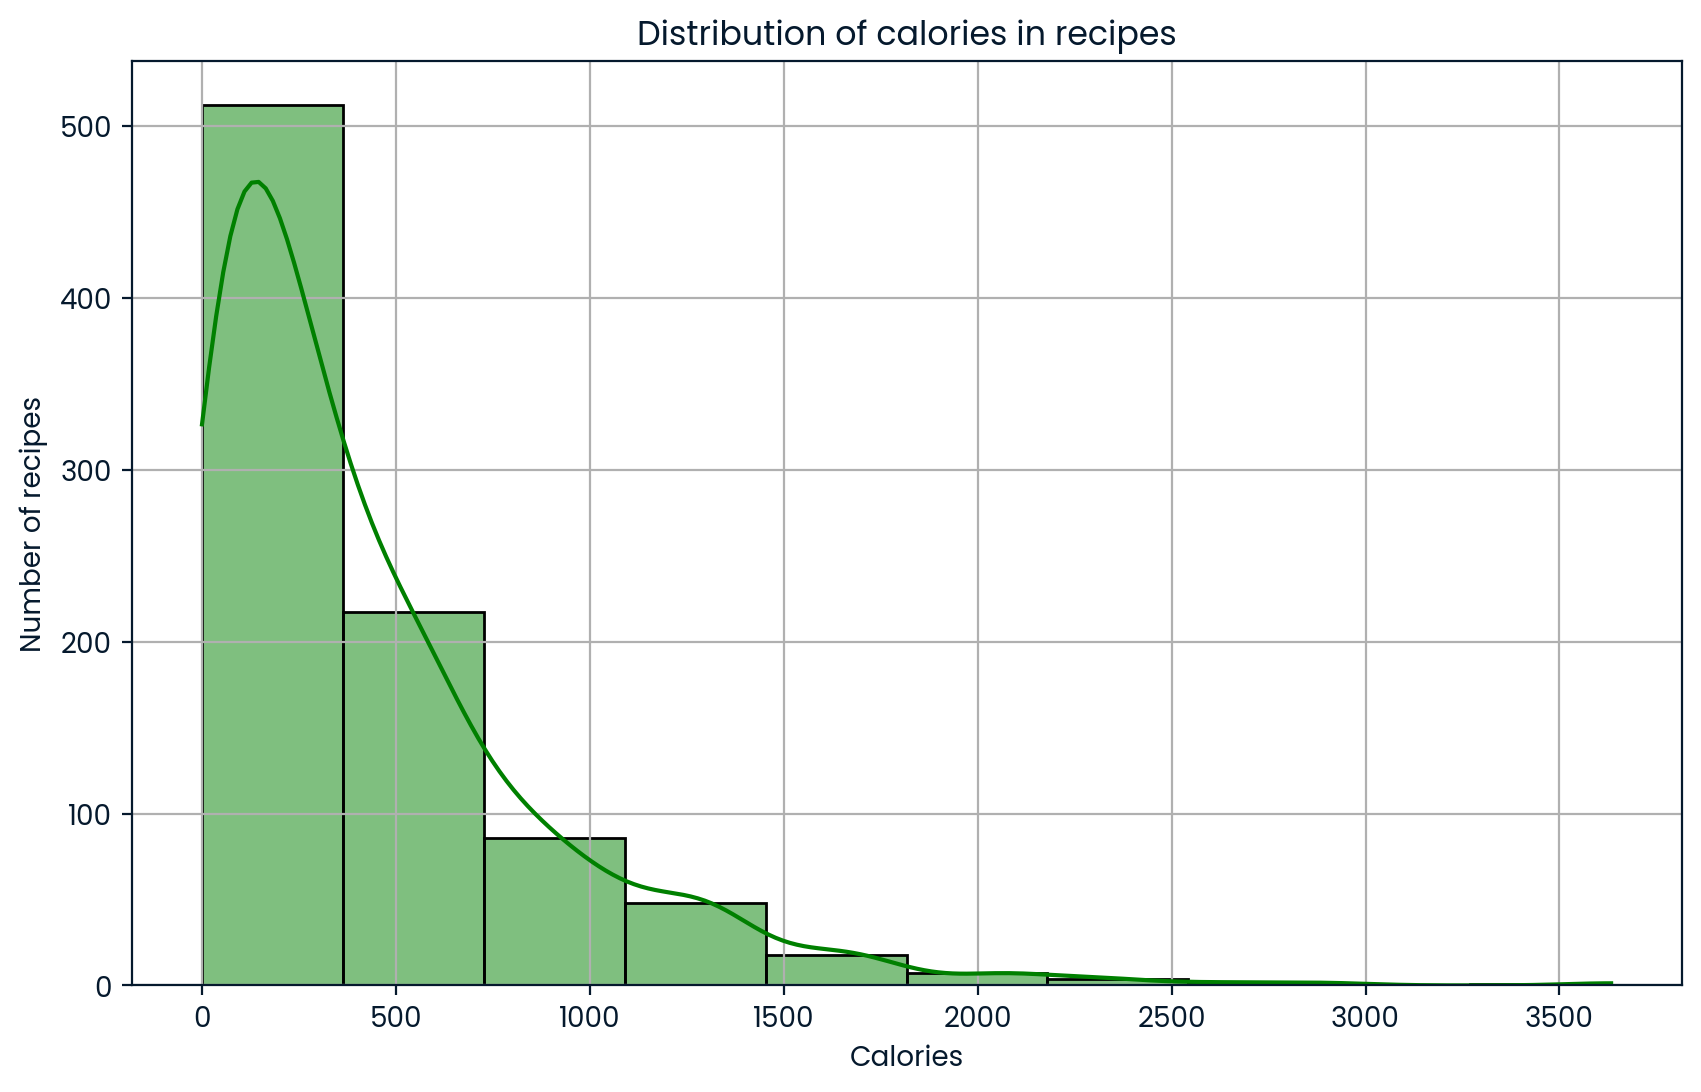

In [343]:
#Creating histogram for the distribution of calories in recipe
calories_data = recipe_site_traffic['calories']
#Set the figure size
plt.figure(figsize=(10,6))
sns.histplot(calories_data, bins=10, color='green', edgecolor='black',kde=True)
#Set x and y label
plt.xlabel("Calories")
plt.ylabel("Number of recipes")
#Set the title of the histogram
plt.title("Distribution of calories in recipes")
#set grid to true
plt.grid(True)
#Display the plot
plt.show()

In [344]:
'''
The presence of Kernel Density Estimation (KDE) in the plots results in a smooth curve that illustrates the underlying data distribution.
The histogram shows most recipes have medium-calorie options available. This indicates a mix of lighter and higher-calorie recipes to suit different preferences.Proceeding to present it using box plots.
'''

'\nThe presence of Kernel Density Estimation (KDE) in the plots results in a smooth curve that illustrates the underlying data distribution.\nThe histogram shows most recipes have medium-calorie options available. This indicates a mix of lighter and higher-calorie recipes to suit different preferences.Proceeding to present it using box plots.\n'

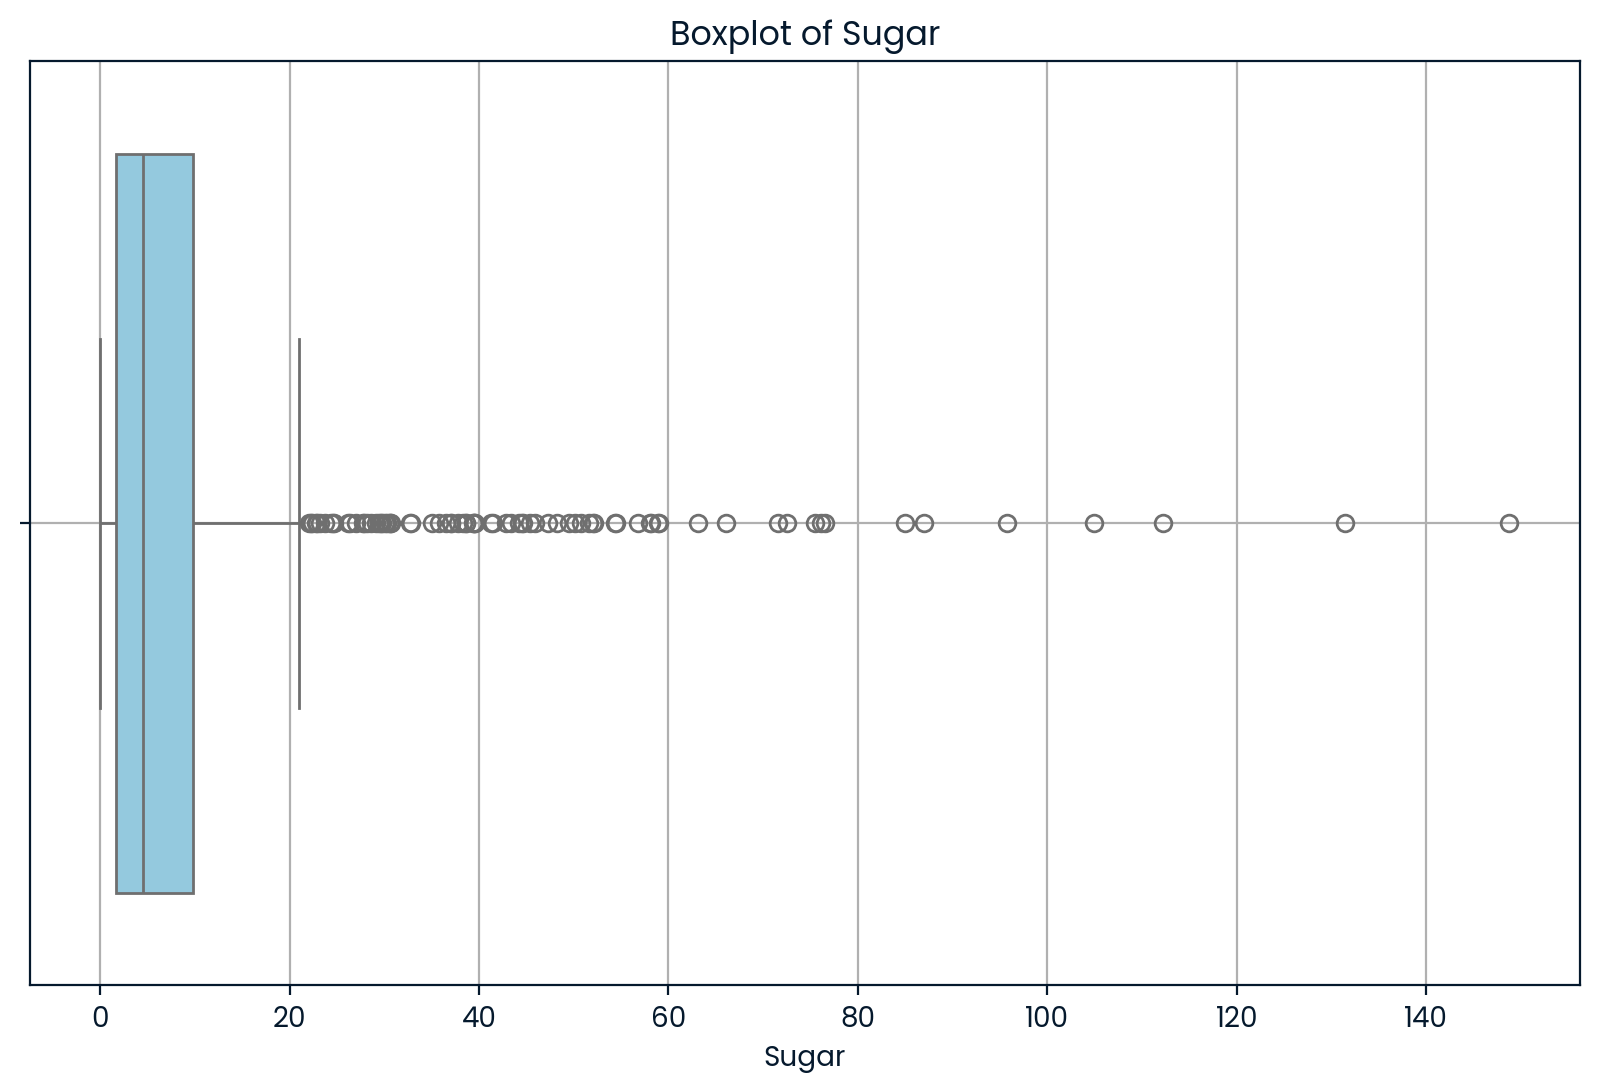

In [345]:
#Boxplot for the sugar column
#Set the figure size
plt.figure(figsize=(10,6))
sns.boxplot(recipe_site_traffic, x= 'sugar', color='skyblue')
plt.title('Boxplot of Sugar')
plt.xlabel('Sugar')
plt.grid(True)
plt.show()

In [346]:
'''Once more, the plots above affirm the existence of outliers, the right-skewed nature of these columns. 
Moving forward, let's examine the relationship between servings and high traffic status.
'''

"Once more, the plots above affirm the existence of outliers, the right-skewed nature of these columns. \nMoving forward, let's examine the relationship between servings and high traffic status.\n"

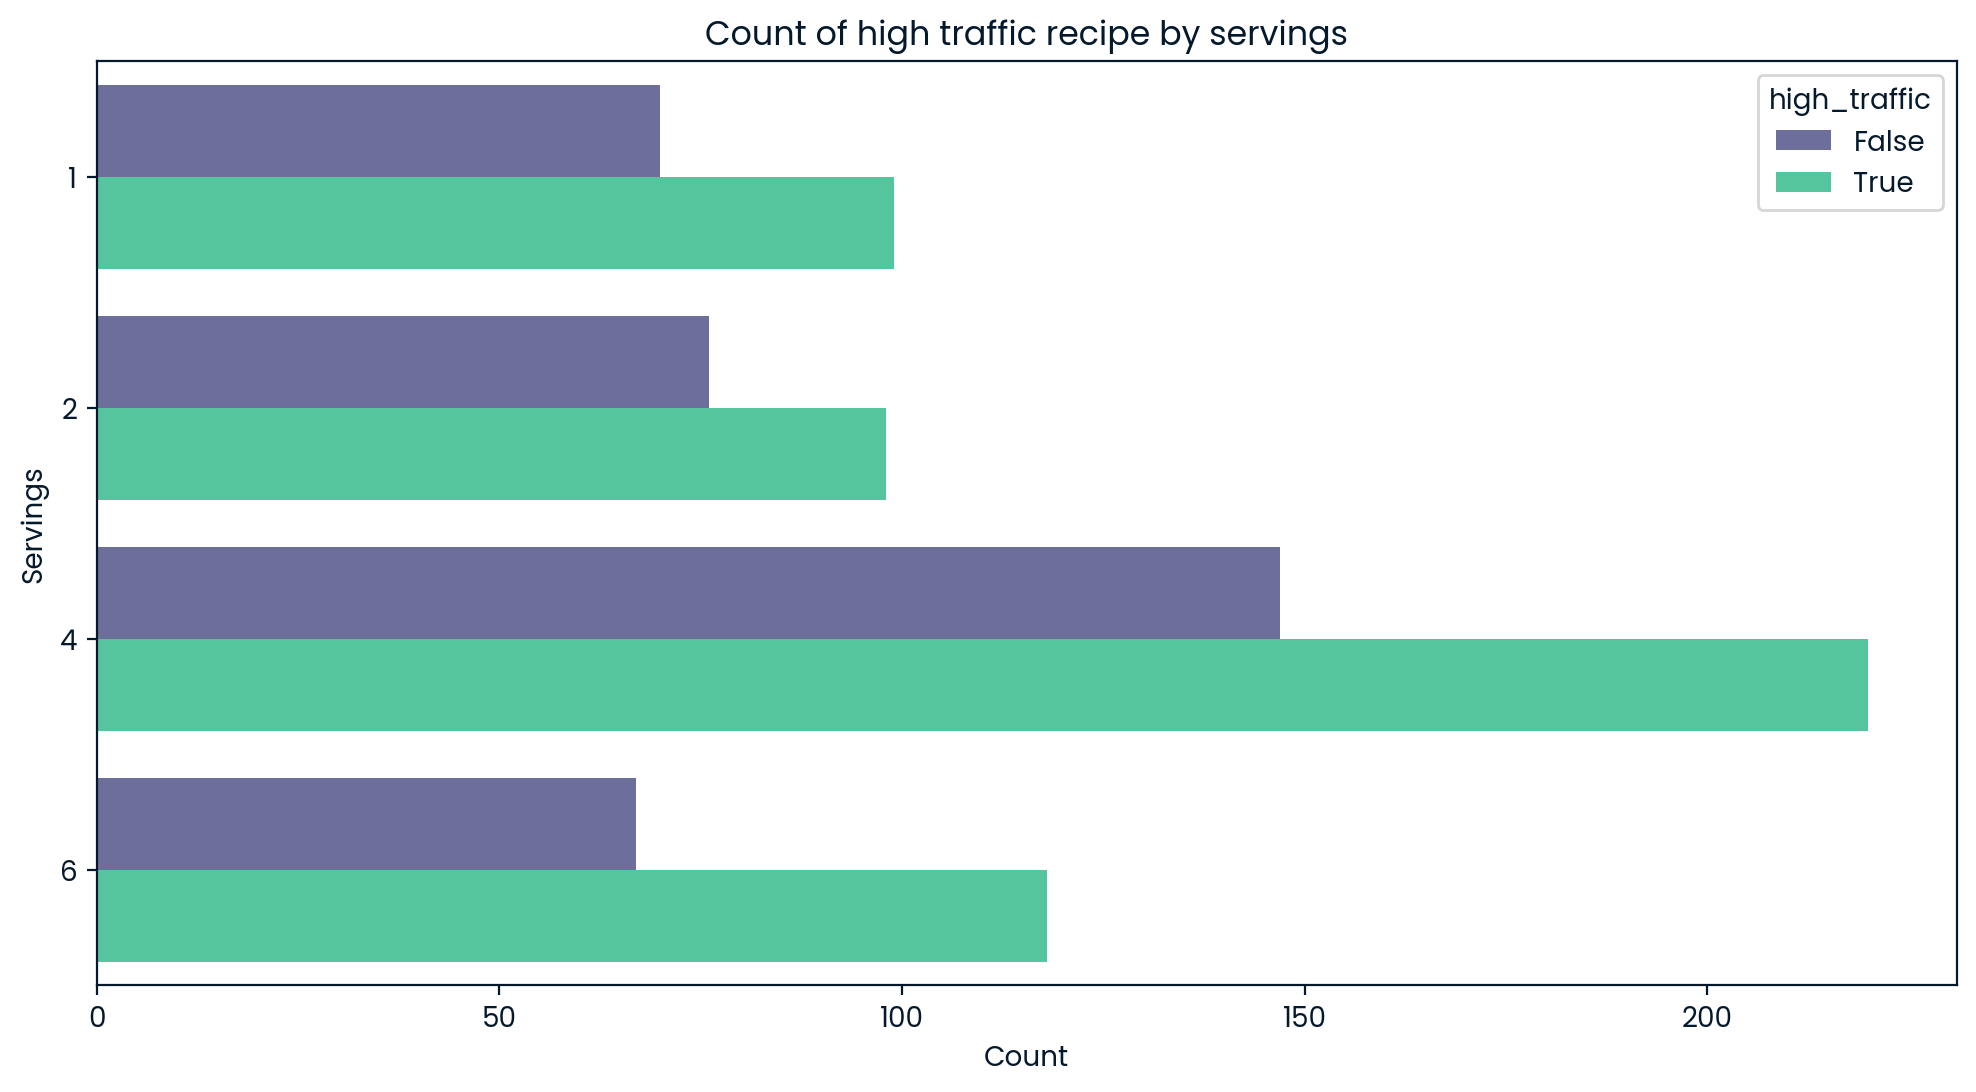

In [347]:
#Using count plot to analyse the relationship between servings and high traffc status
#Set the figure set
plt.figure(figsize=(12,6))
sns.countplot(recipe_site_traffic, y='servings', hue='high_traffic')
#Set x and y label
plt.xlabel('Count')
plt.ylabel('Servings')
#Set tittle of the countplot
plt.title('Count of high traffic recipe by servings')
plt.show()


In [348]:
#Groupby by high traffic for aggregation
high_traffic_servings = recipe_site_traffic.groupby(['servings','high_traffic']).size().unstack()
#Normalize high_traffic_servings to get the rate(ratio) to determine what servings have the highest high traffic rate
normalized_high_traffic_servings = high_traffic_servings.div(high_traffic_servings.sum(axis=1), axis=0)
print(normalized_high_traffic_servings)

high_traffic     False     True 
servings                        
1             0.414201  0.585799
2             0.436782  0.563218
4             0.400545  0.599455
6             0.362162  0.637838


In [349]:
'''Both the plot and the normalized values illustrate that recipes with 6 servings exhibit a higher rate of high traffic.

Next, we'll proceed to examine the relationship between categories and high traffic status.
'''

"Both the plot and the normalized values illustrate that recipes with 6 servings exhibit a higher rate of high traffic.\n\nNext, we'll proceed to examine the relationship between categories and high traffic status.\n"

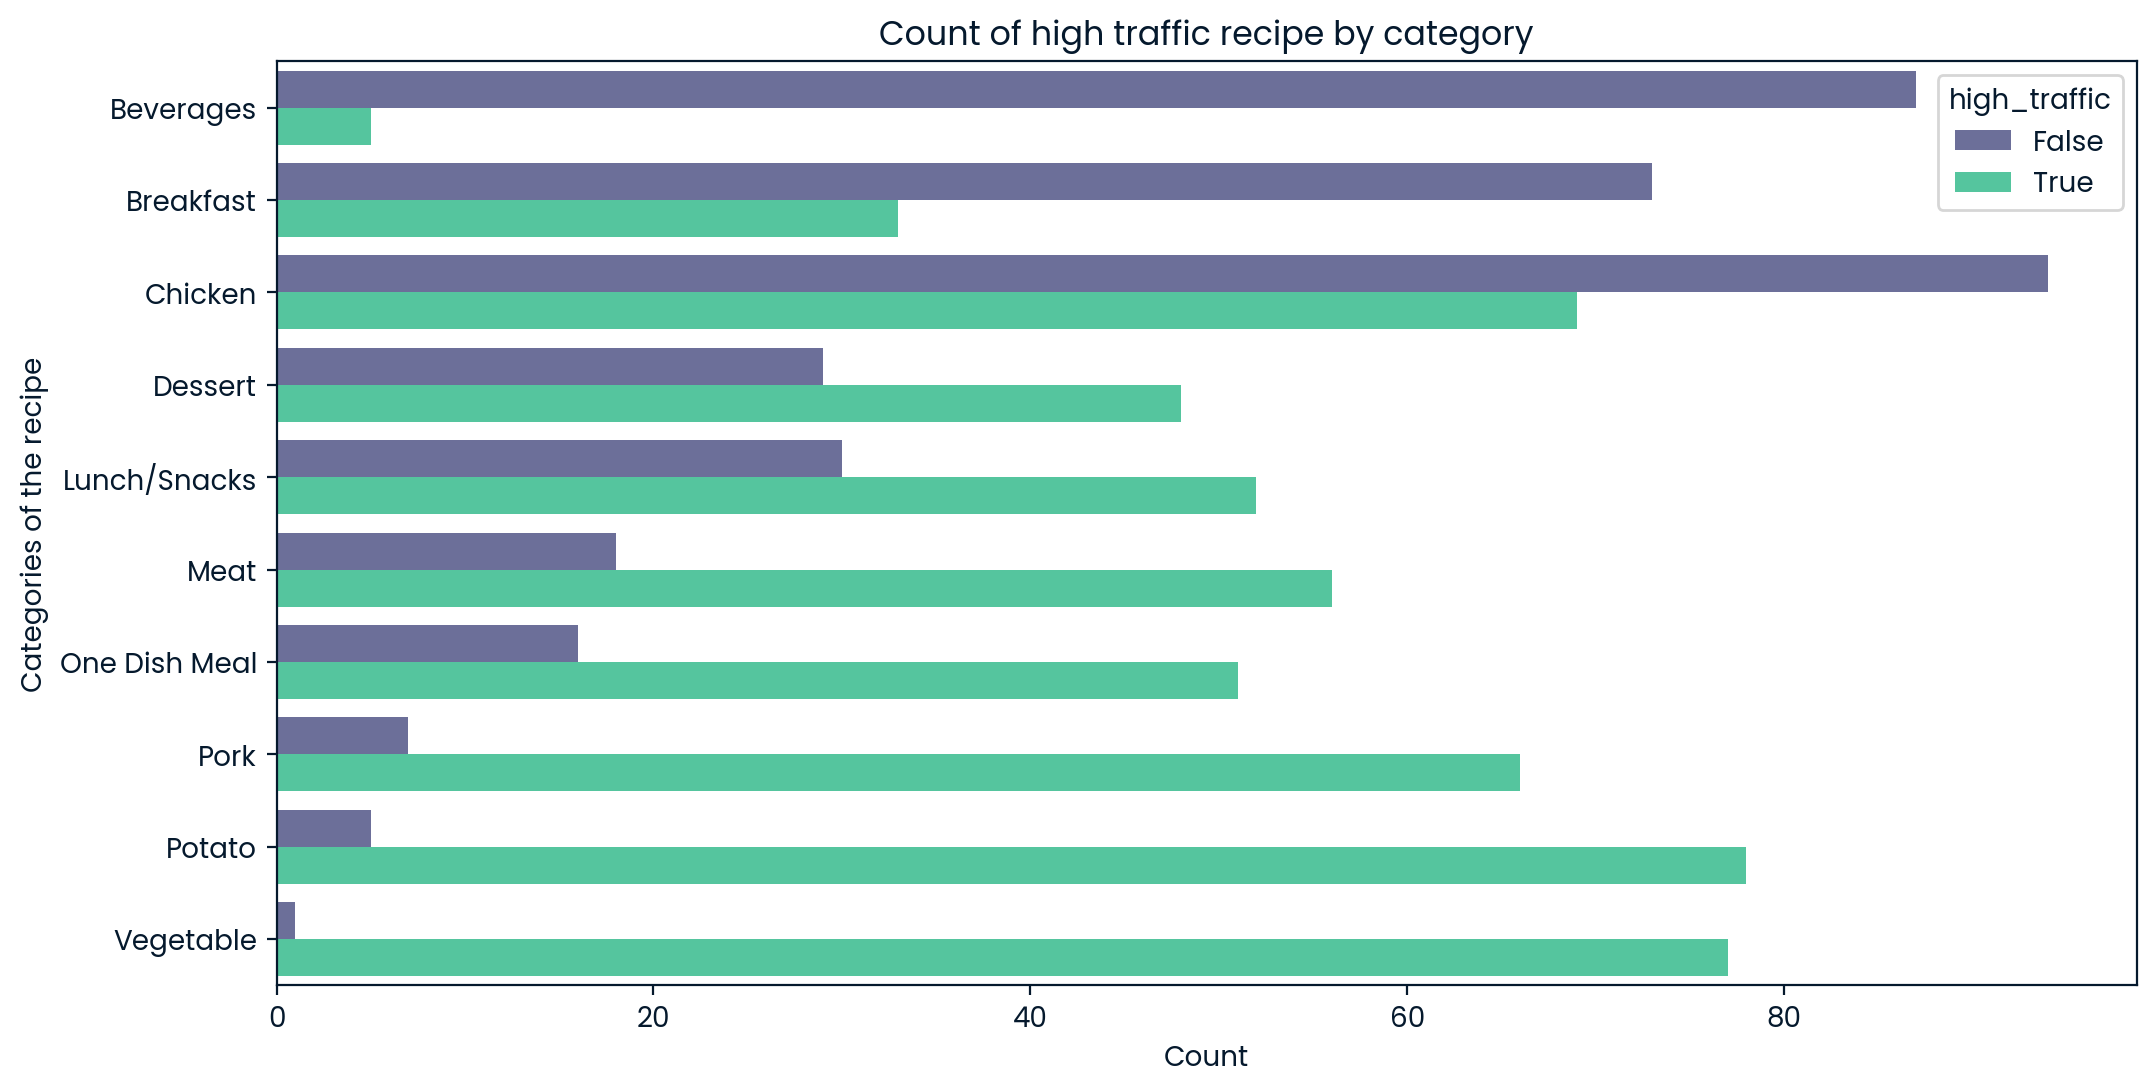

In [350]:
#Set the size of the plot
plt.figure(figsize=(12,6))
sns.countplot(recipe_site_traffic, y='category', hue='high_traffic')
#Set X and y label
plt.xlabel('Count')
plt.ylabel('Categories of the recipe')
#Set title of the countplot
plt.title('Count of high traffic recipe by category')
plt.show()


In [351]:
#Groupby by high traffic for aggregation
high_traffic_category = recipe_site_traffic.groupby(['category','high_traffic']).size().unstack()

##Normalize high_traffic_category to get the rate(ratio) to determine what Category have the highest high traffic rate
normalized_high_traffic_category = high_traffic_category.div(high_traffic_category.sum(axis=1),axis=0)
print(normalized_high_traffic_category)

high_traffic      False     True 
category                         
Beverages      0.945652  0.054348
Breakfast      0.688679  0.311321
Chicken        0.576687  0.423313
Dessert        0.376623  0.623377
Lunch/Snacks   0.365854  0.634146
Meat           0.243243  0.756757
One Dish Meal  0.238806  0.761194
Pork           0.095890  0.904110
Potato         0.060241  0.939759
Vegetable      0.012821  0.987179


In [352]:
'''
Consequently, we can deduce that showcasing recipes in certain categories leads to increased traffic.
The top three categories in terms of high traffic are "Vegetable," "Potato," and "Pork." On the other hand, the "Beverages" category appears to have the lowest traffic impact.'''

'\nConsequently, we can deduce that showcasing recipes in certain categories leads to increased traffic.\nThe top three categories in terms of high traffic are "Vegetable," "Potato," and "Pork." On the other hand, the "Beverages" category appears to have the lowest traffic impact.'

In [353]:
'''To address this task, we will apply binary classification techniques from supervised machine learning. Several models are suitable for predicting high traffic status, including Logistic Regression, Decision Trees, Random Forests, and Support Vector Machines. For our baseline, we’ll start with Logistic Regression and later compare its performance with Decison Tree.

Before building the Logistic Regression model, we need to handle outliers in the dataset. We’ll do this by calculating the Interquartile Range (IQR) for each feature and using it to establish upper and lower bounds to effectively identify and manage outliers.
'''

'To address this task, we will apply binary classification techniques from supervised machine learning. Several models are suitable for predicting high traffic status, including Logistic Regression, Decision Trees, Random Forests, and Support Vector Machines. For our baseline, we’ll start with Logistic Regression and later compare its performance with Decison Tree.\n\nBefore building the Logistic Regression model, we need to handle outliers in the dataset. We’ll do this by calculating the Interquartile Range (IQR) for each feature and using it to establish upper and lower bounds to effectively identify and manage outliers.\n'

In [354]:
#Create a function to the lower and upper limits of column
def calculate_outlier_limits(data,factor = 1.5):
    #Calculate the 25% and 75% of the data
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    #Calculate the iqr
    iqr = q3 - q1
    #Calculate the lower and upper limits
    lower_limit = q1 - (factor * iqr)
    upper_limit = q3 + (factor * iqr)
    return lower_limit, upper_limit

#Using the function above to calculate the outlier limits of each numerical columns
#Select numerical columns
numerical_columns = recipe_site_traffic.select_dtypes(include='float')
outlier_limits = {}
#Loop through the numerical_columns
for col in numerical_columns:
    lower_limit, upper_limit = calculate_outlier_limits(recipe_site_traffic[col])
    outlier_limits[col] = (lower_limit, upper_limit)
#Loop through outlier_limits dictionary to get the values of upper_limit and lower_limit of each numerical col
for col, limits in outlier_limits.items():
    print(f"Column: {col}")
    print(f"Lower limit {limits[0]}")
    print(f"Upper limit {limits[1]}")


Column: calories
Lower limit -620.3999999999999
Upper limit 1328.48
Column: carbohydrate
Lower limit -46.510000000000005
Upper limit 99.85000000000001
Column: sugar
Lower limit -10.475000000000003
Upper limit 21.965000000000003
Column: protein
Lower limit -37.31250000000001
Upper limit 70.70750000000001


In [355]:
'''As expected, low-value outliers are not an issue, but some high-value outliers require attention. Several methods can address this, but simply removing outliers results in excessive data loss, making it impractical. Likewise, techniques like capping or winsorization do not achieve the desired distribution.

the Yeo-Johnson transformation works best for our data.

Since some columns contain zeros, applying the Box-Cox transformation would require substituting zeros with a very small number (e.g., 0.00001), which could introduce bias. Therefore, the Yeo-Johnson method was chosen as the preferred approach.
'''

'As expected, low-value outliers are not an issue, but some high-value outliers require attention. Several methods can address this, but simply removing outliers results in excessive data loss, making it impractical. Likewise, techniques like capping or winsorization do not achieve the desired distribution.\n\nthe Yeo-Johnson transformation works best for our data.\n\nSince some columns contain zeros, applying the Box-Cox transformation would require substituting zeros with a very small number (e.g., 0.00001), which could introduce bias. Therefore, the Yeo-Johnson method was chosen as the preferred approach.\n'

In [356]:
#filter the dataset based on the outlier limits
transformed_data = recipe_site_traffic.copy()
for col, limits in outlier_limits.items():
    lower_limit,upper_limit = limits
    #Applying yeojohnson on the transformed data
    transformed_data[col] = yeojohnson(transformed_data[col])[0]
transformed_data.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,2,5.742713,4.409023,0.481476,0.653469,Potato,4,True
1,3,17.437755,4.550612,1.224094,1.360783,Breakfast,1,False
2,4,8.416476,4.091120,2.587147,0.019804,Beverages,4,True
3,5,5.133412,1.101661,0.553884,0.425754,Beverages,4,False
4,6,16.024490,1.607528,0.883720,4.049462,One Dish Meal,2,True


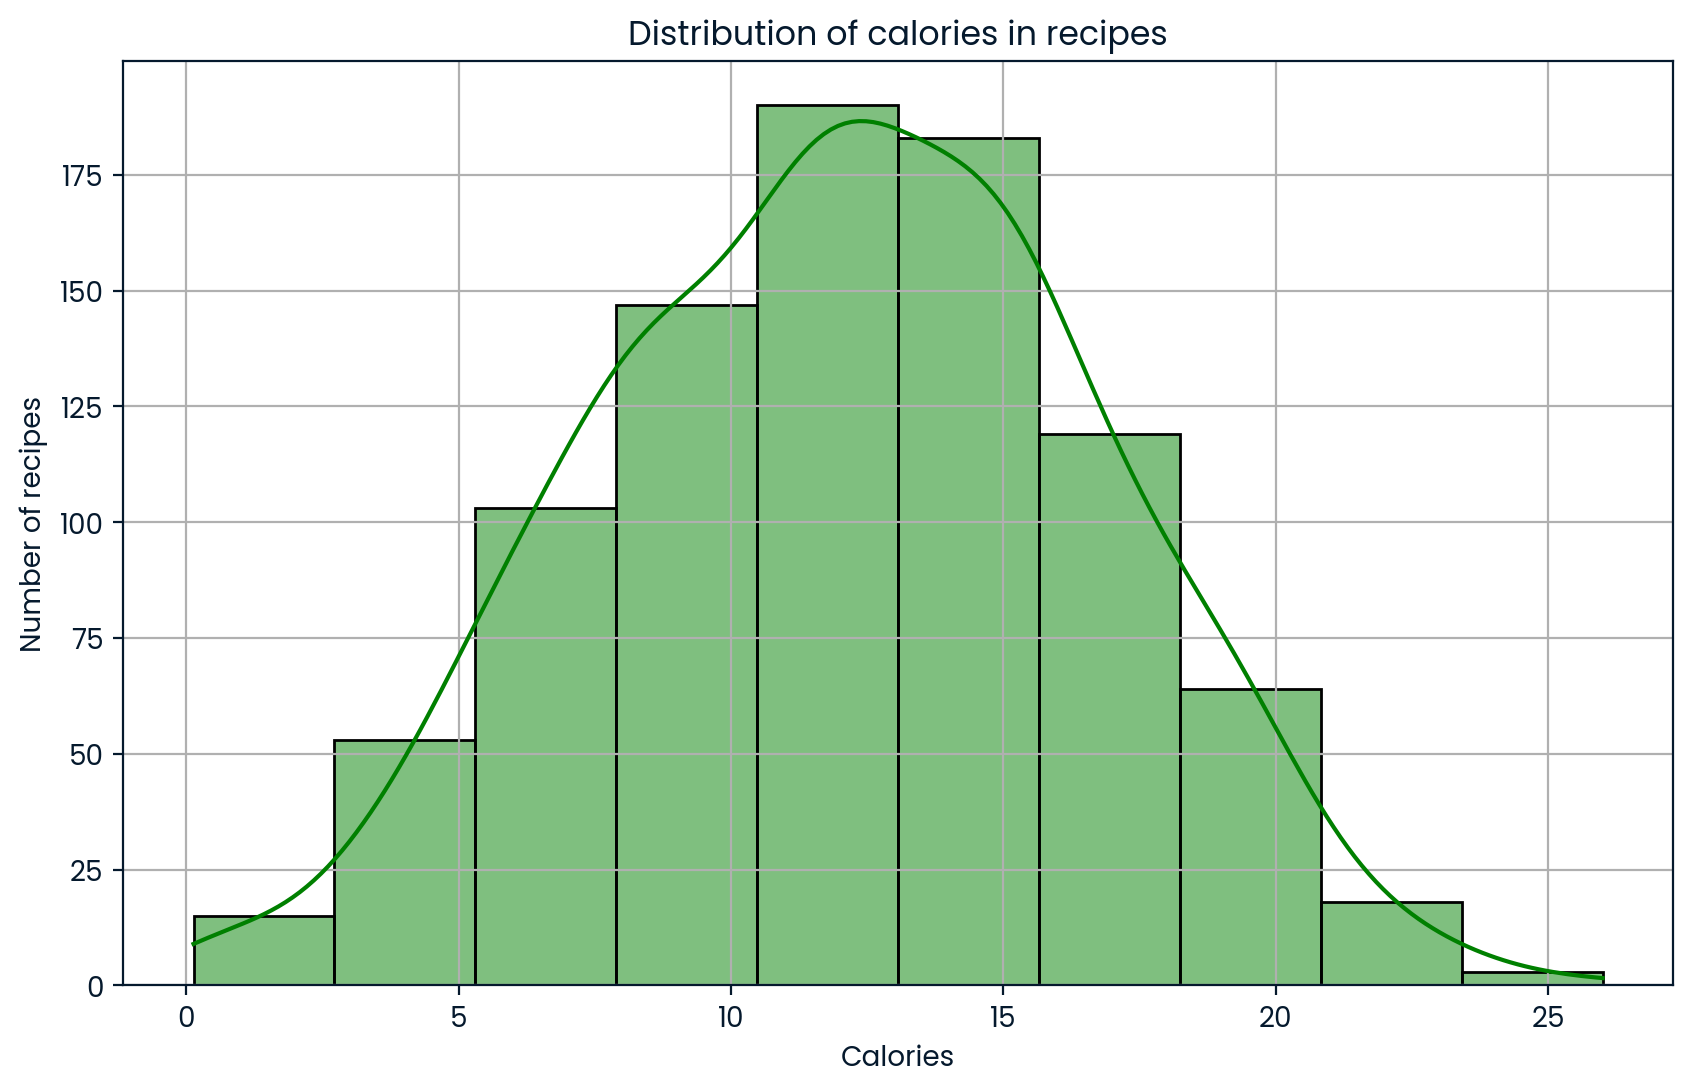

In [357]:
#Creating histogram for the distribution of calories in recipe
calories_data = transformed_data['calories']
#Set the figure size
plt.figure(figsize=(10,6))
sns.histplot(calories_data, bins=10, color='green', edgecolor='black',kde=True)
#Set x and y label
plt.xlabel("Calories")
plt.ylabel("Number of recipes")
#Set the title of the histogram
plt.title("Distribution of calories in recipes")
#set grid to true
plt.grid(True)
#Display the plot
plt.show()

In [358]:
"""Now the distribution of transformed data is normally distrubted"""

'Now the distribution of transformed data is normally distrubted'

In [359]:
#Perform one-hot encoding on category column
encoded_category = pd.get_dummies(recipe_site_traffic['category'])
#Concatinate the encoded column with the original dataframe
recipe_site_traffic_encoded = pd.concat([transformed_data, encoded_category], axis =1)
#Drop the category column
recipe_site_traffic_encoded = recipe_site_traffic_encoded.drop('category', axis=1)
#Display the first five rows of the dataframe
recipe_site_traffic_encoded.head()

,recipe,calories,carbohydrate,sugar,protein,servings,high_traffic,Beverages,Breakfast,Chicken,Dessert,Lunch/Snacks,Meat,One Dish Meal,Pork,Potato,Vegetable
0,2,5.742713,4.409023,0.481476,0.653469,4,True,0,0,0,0,0,0,0,0,1,0
1,3,17.437755,4.550612,1.224094,1.360783,1,False,0,1,0,0,0,0,0,0,0,0
2,4,8.416476,4.091120,2.587147,0.019804,4,True,1,0,0,0,0,0,0,0,0,0
3,5,5.133412,1.101661,0.553884,0.425754,4,False,1,0,0,0,0,0,0,0,0,0
4,6,16.024490,1.607528,0.883720,4.049462,2,True,0,0,0,0,0,0,1,0,0,0


In [360]:
'''Our next steps are as follows:

First, we’ll separate the dataset into features (X) and the target variable (y), with “high_traffic” as the target. Then, using scikit-learn’s train_test_split, we’ll split the data into training and testing sets.

We’ll build the baseline model alongside other comparison models. After fitting the selected model to the training data, we’ll use it to make predictions on the test set. We’ll also use the model’s predict method on training data to check for potential overfitting.

With this plan in place, we can now proceed to develop the baseline and comparison machine learning models.
'''

'Our next steps are as follows:\n\nFirst, we’ll separate the dataset into features (X) and the target variable (y), with “high_traffic” as the target. Then, using scikit-learn’s train_test_split, we’ll split the data into training and testing sets.\n\nWe’ll build the baseline model alongside other comparison models. After fitting the selected model to the training data, we’ll use it to make predictions on the test set. We’ll also use the model’s predict method on training data to check for potential overfitting.\n\nWith this plan in place, we can now proceed to develop the baseline and comparison machine learning models.\n'

In [361]:
# Select all columns expect our target column 'high_traffic' for X
X = recipe_site_traffic_encoded.drop('high_traffic', axis= 1)
#Select our target column
y = recipe_site_traffic_encoded['high_traffic']
#Split our data to train and test data 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42)
#Develop a function to fit, predict and calculate the model's evaluation metrics for both test and trian data
def develop_model(model, X_train, X_test, y_train, y_test ):
    evaluation_metrics = {}
    #fit the train data
    model.fit(X_train,y_train)
    #Predict train data
    model_predict_train = model.predict(X_train)
    #Preidct test data
    model_predict_test = model.predict(X_test)

    #Calculating the evaluation metrics for train data
    model_accuracy_train = accuracy_score(model_predict_train, y_train)
    model_precision_train = precision_score(model_predict_train, y_train)
    model_recall_train = recall_score(model_predict_train, y_train)
    model_f1_score_train = f1_score(model_predict_train, y_train)
    model_cm_train = confusion_matrix(model_predict_train, y_train)

    evaluation_metrics['train'] = [model_accuracy_train, model_precision_train, model_recall_train, model_f1_score_train, model_cm_train]



    #Calculating the evaluation metrics for test data
    model_accuracy_test = accuracy_score(model_predict_test, y_test)
    model_precision_test = precision_score(model_predict_test, y_test)
    model_recall_test = recall_score(model_predict_test, y_test)
    model_f1_score_test = f1_score(model_predict_test, y_test)
    model_cm_test = confusion_matrix(model_predict_test, y_test)

    evaluation_metrics['test'] = [model_accuracy_test, model_precision_test, model_recall_test, model_f1_score_test, model_cm_test]
    return evaluation_metrics

In [362]:
#Instanstiate LogisticRegression
logreg = LogisticRegression()
#Apply the function 'develop_model' to get logisticRegression evaluation metrics
logreg_evaluation_metrics = develop_model(logreg, X_train, X_test, y_train, y_test)

#Instanstiate DecisionTreeClassifier
ds = DecisionTreeClassifier()
#Apply the function 'develop_model' to get DecisionTreeClassifier evaluation metrics
ds_evaluation_metrics = develop_model(ds, X_train, X_test, y_train, y_test)


In [363]:
#Write a function to print metrics in 'evaluation_metrics' dictionary using index number
def print_metrics(evaluation_metrics):
    print("Accuracy score:", evaluation_metrics[0])
    print("Precision score:", evaluation_metrics[1])
    print("Recall score:", evaluation_metrics[2])
    print("F1 score:", evaluation_metrics[3])
    print("Confusion Matrix:",)
    print(evaluation_metrics[4])

print("Logistic Regression Train")
print_metrics(logreg_evaluation_metrics['train'])

print("Logistic Regression Test")
print_metrics(logreg_evaluation_metrics['test'])


Logistic Regression Train
Accuracy score: 0.7472067039106145
Precision score: 0.8135198135198135
Recall score: 0.7755555555555556
F1 score: 0.7940841865756542
Confusion Matrix:
[[186  80]
 [101 349]]
Logistic Regression Test
Accuracy score: 0.770949720670391
Precision score: 0.839622641509434
Recall score: 0.7876106194690266
F1 score: 0.812785388127854
Confusion Matrix:
[[49 17]
 [24 89]]


In [364]:
'''The Logistic Regression model demonstrates very similar performance on both the training and test datasets, indicating that the model generalizes well without signs of overfitting. The slightly higher results on the test data are likely due to natural variation in the data samples rather than a limitation in dataset size. Given that our goal is to achieve at least 80% accuracy in predicting high traffic recipes, it is important to also consider the precision metric, which stands at approximately 80%. This means that when the model predicts a recipe as high traffic, it is correct about 80% of the time, aligning well with our performance objectives.'''

'The Logistic Regression model demonstrates very similar performance on both the training and test datasets, indicating that the model generalizes well without signs of overfitting. The slightly higher results on the test data are likely due to natural variation in the data samples rather than a limitation in dataset size. Given that our goal is to achieve at least 80% accuracy in predicting high traffic recipes, it is important to also consider the precision metric, which stands at approximately 80%. This means that when the model predicts a recipe as high traffic, it is correct about 80% of the time, aligning well with our performance objectives.'

In [365]:
print("Decision Tree Regression Train")
print_metrics(ds_evaluation_metrics['train'])

print("Decision Tree Regression Train")
print_metrics(ds_evaluation_metrics['test'])

Decision Tree Regression Train
Accuracy score: 1.0
Precision score: 1.0
Recall score: 1.0
F1 score: 1.0
Confusion Matrix:
[[287   0]
 [  0 429]]
Decision Tree Regression Train
Accuracy score: 0.6424581005586593
Precision score: 0.7075471698113207
Recall score: 0.6944444444444444
F1 score: 0.7009345794392523
Confusion Matrix:
[[40 31]
 [33 75]]


In [366]:
'''The Decision Tree model has exhibited clear signs of overfitting, demonstrated by perfect accuracy on the training data but significantly lower performance on the test data. This suggests the model has memorized the training examples rather than learning generalizable patterns, a common issue when working with limited data.

Although techniques such as increasing the training data size, applying regularization methods, and using cross-validation can help mitigate overfitting, their effectiveness is often limited when the dataset is small.

Therefore, given its overfitting tendencies, the Decision Tree may not be the best choice for our dataset. Alternative models or approaches that better control overfitting might be more suitable.

'''

'The Decision Tree model has exhibited clear signs of overfitting, demonstrated by perfect accuracy on the training data but significantly lower performance on the test data. This suggests the model has memorized the training examples rather than learning generalizable patterns, a common issue when working with limited data.\n\nAlthough techniques such as increasing the training data size, applying regularization methods, and using cross-validation can help mitigate overfitting, their effectiveness is often limited when the dataset is small.\n\nTherefore, given its overfitting tendencies, the Decision Tree may not be the best choice for our dataset. Alternative models or approaches that better control overfitting might be more suitable.\n\n'

In [367]:
'''
We can establish a Key Performance Indicator (KPI) by dividing True Positives (high recipes correctly classified as high) by False Positives (low recipes mistakenly classified as high) within the confusion matrix. This KPI, which we can refer to as the "High Traffic Conversion Rate," needs to be maintained at a level equal to or greater than 4.0, relying on the train and test results of our baseline model. This KPI can serve as a valuable metric for our business model, providing insights into the accuracy of high traffic predictions.'''

'\nWe can establish a Key Performance Indicator (KPI) by dividing True Positives (high recipes correctly classified as high) by False Positives (low recipes mistakenly classified as high) within the confusion matrix. This KPI, which we can refer to as the "High Traffic Conversion Rate," needs to be maintained at a level equal to or greater than 4.0, relying on the train and test results of our baseline model. This KPI can serve as a valuable metric for our business model, providing insights into the accuracy of high traffic predictions.'

In [368]:
# KPI calculation
def calculate_kpi(model_metrics, model_name):
    kpi_train = model_metrics['train'][4]
    kpi_test = model_metrics['test'][4]
    print(f"High Traffic Conversion Rate for {model_name} train: ", kpi_train[1][1]/(kpi_train[0][1]))
    print(f"High Traffic Conversion Rate for {model_name} test: ", kpi_test[1][1]/(kpi_test[0][1]))

In [370]:
#KPI calculation for Logistic Regression
calculate_kpi(logreg_evaluation_metrics, "Logistic Regresssion")


#KPI calculation for Decision Tree
calculate_kpi(ds_evaluation_metrics, "Decision Tree")
print

High Traffic Conversion Rate for Logistic Regresssion train:  4.3625
High Traffic Conversion Rate for Logistic Regresssion test:  5.235294117647059
High Traffic Conversion Rate for Decision Tree train:  inf
High Traffic Conversion Rate for Decision Tree test:  2.4193548387096775


<function print>

In [ ]:
'''
In the training results of the Decision Tree  the "KPI = inf" occurs due to overfitting. Furthermore, the test result for the model fall short of meeting our predetermined KPI requirement.

Ultimately, in our baseline Logistic Regression model, both the training and testing results successfully adhere to our KPI requirement.'''

In [371]:
'''# SUMMARY

In summary, we developed and evaluated multiple models to achieve our goal. Among these, the logistic regression model proved to be the best performer, making it the ideal choice for predicting high-traffic recipes with an accuracy of around 80%.

From a business perspective, misclassifying a high-traffic recipe as low traffic is a more critical error than the reverse. Therefore, our main focus is on model precision, since failing to identify a popular recipe can cause significant business losses.

We also introduced a custom Key Performance Indicator (KPI) called the "High Traffic Conversion Rate," based on the results of our baseline model. This KPI helps us compare the effectiveness of different models.

Our exploratory analysis revealed that certain recipe categories consistently attract either high or low traffic. Recipes in the "Vegetable," "Potato," or "Pork" categories tend to drive high traffic and are recommended for featuring on the website. In contrast, "Beverages" recipes typically attract low traffic and are less suitable for the platform.
'''

'# SUMMARY\n\nIn summary, we developed and evaluated multiple models to achieve our goal. Among these, the logistic regression model proved to be the best performer, making it the ideal choice for predicting high-traffic recipes with an accuracy of around 80%.\n\nFrom a business perspective, misclassifying a high-traffic recipe as low traffic is a more critical error than the reverse. Therefore, our main focus is on model precision, since failing to identify a popular recipe can cause significant business losses.\n\nWe also introduced a custom Key Performance Indicator (KPI) called the "High Traffic Conversion Rate," based on the results of our baseline model. This KPI helps us compare the effectiveness of different models.\n\nOur exploratory analysis revealed that certain recipe categories consistently attract either high or low traffic. Recipes in the "Vegetable," "Potato," or "Pork" categories tend to drive high traffic and are recommended for featuring on the website. In contrast, 